# Phase 9.2: Portfolio Construction, Target-Weight Generation & Verification

**Project:** Machine-Learning-Based Sector Rotation Regime Discovery in the Indian Equity Market  
**Phase:** 9.2  
**Authoritative Inputs:**  
- Recovered Causal HMM Probabilities: `results/regime_discovery/hmm_causal_probabilities.csv` (`prob_0` .. `prob_5`)
- Aligned Sector Price Data: `data/processed/aligned/` (`AUTO`, `BANK`, `FMCG`, `IT`, `METAL`, `PHARMA`)
- Authoritative Rules Engine: `src/regime_rotation_rules.py`
- Pipeline Orchestration Module: `src/portfolio_construction.py`

---

### Scope and Frozen Strategy Specifications
1. **Four Strategy Variants:**
   - **Variant 1A:** Template A (100% equity, 0% cash), Equal-Weighted Top-2 candidate sectors.
   - **Variant 1B:** Template A (100% equity, 0% cash), 20-day Inverse-Volatility-Weighted Top-2 candidate sectors.
   - **Variant 2A:** Template B (Defensive cash floor: R0/R2/R4: 0%, R1: 30%, R3: 40%, R5: 20%), Equal-Weighted.
   - **Variant 2B:** Template B (Defensive cash floor), 20-day Inverse-Volatility-Weighted.
2. **Operational Rules:**
   - **Confidence Threshold:** Maximum causal probability $\ge 0.50$.
   - **Minimum Holding Lockup:** 5 trading days between elective rebalances.
   - **Crisis Override:** Confirmed transition to Regime 3 immediately bypasses 5-day lockup.
   - **Execution Timing:** Signal at Date $t$ Close $\rightarrow$ Execution at Date $t+1$ Close (zero look-ahead bias).
   - **Initial State (Day 0):** Initialized to 100% NIFTY 50 benchmark; first rebalance carries 100% turnover.
   - **Train-to-Holdout Continuity:** Seamless sequential execution across the `2024-12-31` to `2025-01-02` boundary with zero reset.

> **Strict Boundary:** This phase generates, validates, and persists target-weight schedules only. Portfolio profitability, CAGR, Sharpe ratio, drawdowns, equity curves, and performance attribution are strictly prohibited here and deferred to Phase 10.

## 1. Environment Setup and Imports

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import Phase 9.2 portfolio construction orchestration and Phase 8 rules engine
from src.portfolio_construction import (
    EXPECTED_TOTAL_SESSIONS,
    EXPECTED_TRAIN_SESSIONS,
    EXPECTED_HOLDOUT_SESSIONS,
    EXPECTED_TRAIN_START,
    EXPECTED_TRAIN_END,
    EXPECTED_HOLDOUT_START,
    EXPECTED_HOLDOUT_END,
    PROB_COLS,
    WEIGHT_COLS,
    SCHEDULE_COLUMNS,
    load_causal_probabilities,
    load_aligned_prices,
    validate_probabilities_df,
    validate_price_coverage,
    validate_timeline_partition,
    validate_schedule,
    generate_portfolio_schedule,
    generate_all_schedules,
    save_target_weight_schedules,
    reload_and_verify_schedules,
    run_portfolio_construction_pipeline,
)
from src.regime_rotation_rules import (
    SECTOR_NAMES,
    ALL_ASSETS,
    REGIME_SECTORS,
    TEMPLATE_A_CASH,
    TEMPLATE_B_CASH,
)

print("Environment initialized successfully.")
print(f"Project root: {project_root}")

Environment initialized successfully.
Project root: c:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery


## 2. Input-File Inventory and Schema Validation

In [2]:
# Load causal probabilities and aligned sector prices
prob_df = load_causal_probabilities()
price_df = load_aligned_prices()

print(f"Causal Probabilities Loaded: {len(prob_df)} sessions across {len(prob_df.columns)} columns")
print(f"Columns: {list(prob_df.columns)}")
print(f"Sector Prices Loaded: {len(price_df)} sessions across {list(price_df.columns)}")

# Validate probability simplex constraints
validate_probabilities_df(prob_df)
print("Probability simplex validation passed (finite, bounded [0, 1], row sums = 1.0).")

Causal Probabilities Loaded: 1687 sessions across 7 columns
Columns: ['period', 'prob_0', 'prob_1', 'prob_2', 'prob_3', 'prob_4', 'prob_5']
Sector Prices Loaded: 1886 sessions across ['AUTO', 'BANK', 'FMCG', 'IT', 'METAL', 'PHARMA']
Probability simplex validation passed (finite, bounded [0, 1], row sums = 1.0).


## 3. Timeline Partition Verification and Price Coverage Alignment

In [3]:
# Reconcile session counts against frozen project timeline
timeline_meta = validate_timeline_partition(prob_df)
for k, v in timeline_meta.items():
    print(f"  {k:<18}: {v}")

# Verify price coverage and historical volatility warmup
validate_price_coverage(price_df, prob_df.index, lookback=20)
warmup_count = len(price_df.index[price_df.index < prob_df.index.min()])
print(f"Historical price warmup sessions prior to Day 0: {warmup_count} sessions (>= 20 required).")

  total_sessions    : 1687
  train_sessions    : 1265
  holdout_sessions  : 422
  train_start       : 2019-10-31
  train_end         : 2024-12-31
  holdout_start     : 2025-01-02
  holdout_end       : 2026-09-18
Historical price warmup sessions prior to Day 0: 199 sessions (>= 20 required).


## 4. Full Timeline Schedule Generation (Variants 1A, 1B, 2A, 2B)

Target-weight schedules are generated as a single continuous sequential run across the entire timeline (1,687 trading sessions), ensuring that the portfolio state, accepted regime, and holding clock carry seamlessly across the train-to-holdout boundary without artificial reinitialization.

In [4]:
# Generate schedules for all four variants
schedules = generate_all_schedules(prob_df, price_df)

for v, sched in schedules.items():
    rebal_tot = int(sched["rebalance_triggered"].sum())
    rebal_tr = int(sched[sched["period"] == "train"]["rebalance_triggered"].sum())
    rebal_ho = int(sched[sched["period"] == "holdout"]["rebalance_triggered"].sum())
    mean_turn = float(sched["turnover"].mean() * 100.0)
    print(f"Variant {v}: Total Sessions = {len(sched)} | Rebalances = {rebal_tot} (Train: {rebal_tr}, Holdout: {rebal_ho}) | Mean Daily Turnover = {mean_turn:.2f}%")

Variant 1A: Total Sessions = 1687 | Rebalances = 58 (Train: 38, Holdout: 20) | Mean Daily Turnover = 2.99%
Variant 1B: Total Sessions = 1687 | Rebalances = 58 (Train: 38, Holdout: 20) | Mean Daily Turnover = 3.06%
Variant 2A: Total Sessions = 1687 | Rebalances = 58 (Train: 38, Holdout: 20) | Mean Daily Turnover = 3.04%
Variant 2B: Total Sessions = 1687 | Rebalances = 58 (Train: 38, Holdout: 20) | Mean Daily Turnover = 3.09%


## 5. Separate Training and Protected Holdout Diagnostics

In [5]:
# Diagnostics breakdown table
diag_records = []
for v, sched in schedules.items():
    for p in ["train", "holdout", "full"]:
        sub = sched if p == "full" else sched[sched["period"] == p]
        diag_records.append({
            "Variant": v,
            "Period": p,
            "Sessions": len(sub),
            "Rebalances": int(sub["rebalance_triggered"].sum()),
            "R3 Overrides": int(sub["rebalance_bypassed_r3"].sum()),
            "Mean Daily Turnover (%)": round(float(sub["turnover"].mean() * 100.0), 3),
            "Max Turnover (%)": round(float(sub["turnover"].max() * 100.0), 1),
            "Avg Cash Weight (%)": round(float(sub["w_CASH"].mean() * 100.0), 2),
        })

diag_df = pd.DataFrame(diag_records)
display(diag_df)

,Variant,Period,Sessions,Rebalances,R3 Overrides,Mean Daily Turnover (%),Max Turnover (%),Avg Cash Weight (%)
0,1A,train,1265,38,1,2.569,100.0,0.00
1,1A,holdout,422,20,0,4.265,100.0,0.00
2,1A,full,1687,58,1,2.993,100.0,0.00
3,1B,train,1265,38,1,2.642,100.0,0.00
4,1B,holdout,422,20,0,4.310,100.0,0.00
5,1B,full,1687,58,1,3.059,100.0,0.00
6,2A,train,1265,38,1,2.605,100.0,5.03
7,2A,holdout,422,20,0,4.336,100.0,5.83
8,2A,full,1687,58,1,3.038,100.0,5.23
9,2B,train,1265,38,1,2.660,100.0,5.03


## 6. Target Allocation Visualizations Across Full Timeline

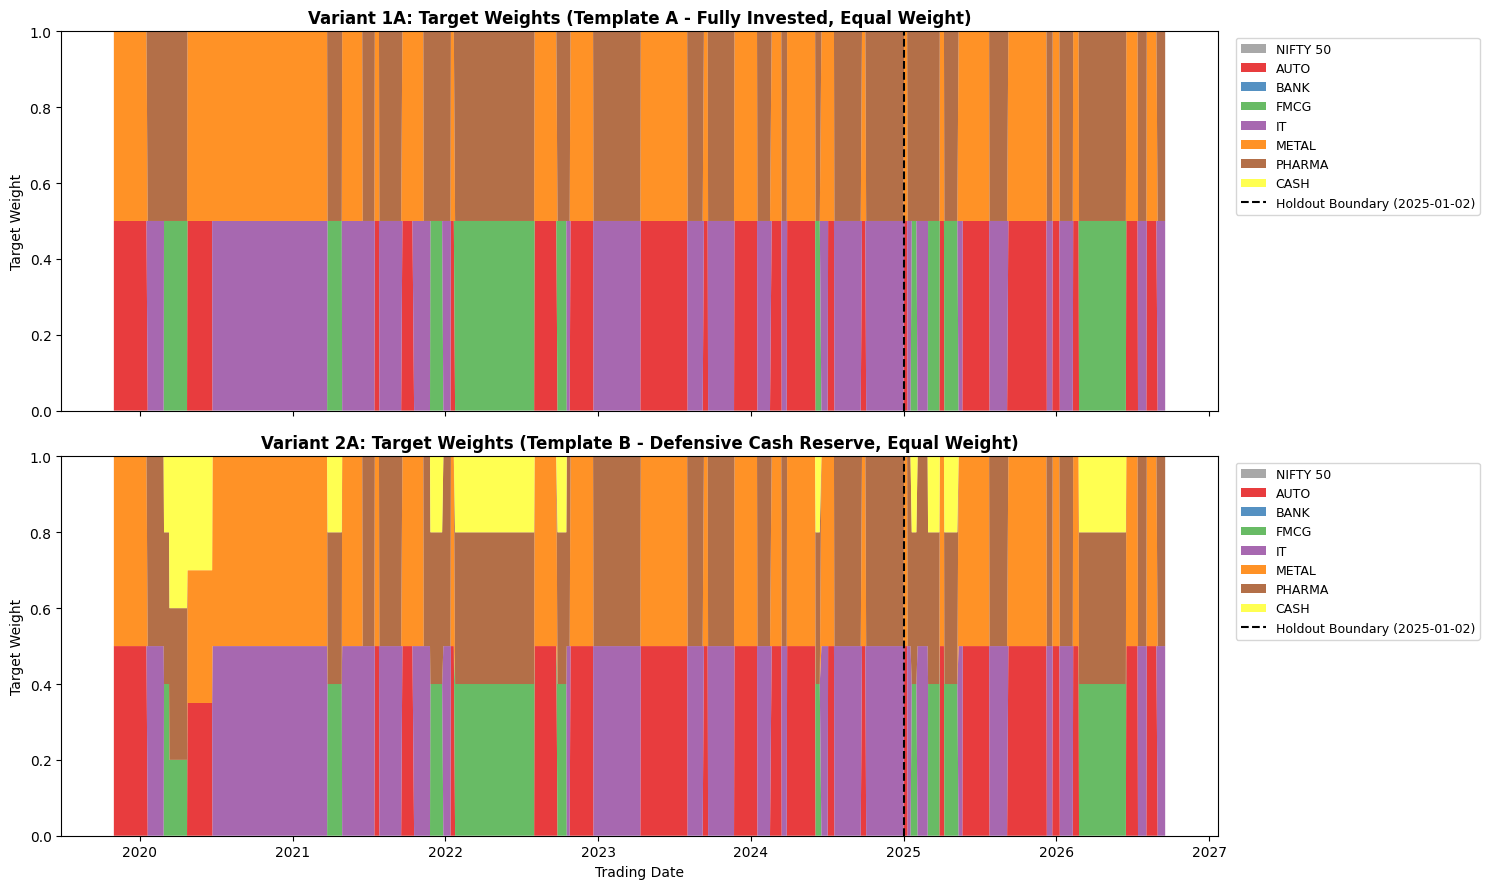

In [6]:
# Plot allocation timeline ribbons for Variant 1A and Variant 2A
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

colors = ["#999999", "#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#ffff33"]
plot_assets = ["w_NIFTY50"] + [f"w_{s}" for s in SECTOR_NAMES] + ["w_CASH"]
labels = ["NIFTY 50"] + SECTOR_NAMES + ["CASH"]

# Variant 1A
sched_1a = schedules["1A"]
axes[0].stackplot(sched_1a.index, [sched_1a[c] for c in plot_assets], labels=labels, colors=colors, alpha=0.85)
axes[0].axvline(pd.Timestamp("2025-01-02"), color="black", linestyle="--", linewidth=1.5, label="Holdout Boundary (2025-01-02)")
axes[0].set_title("Variant 1A: Target Weights (Template A - Fully Invested, Equal Weight)", fontweight="bold")
axes[0].set_ylabel("Target Weight")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
axes[0].set_ylim(0, 1.0)

# Variant 2A
sched_2a = schedules["2A"]
axes[1].stackplot(sched_2a.index, [sched_2a[c] for c in plot_assets], labels=labels, colors=colors, alpha=0.85)
axes[1].axvline(pd.Timestamp("2025-01-02"), color="black", linestyle="--", linewidth=1.5, label="Holdout Boundary (2025-01-02)")
axes[1].set_title("Variant 2A: Target Weights (Template B - Defensive Cash Reserve, Equal Weight)", fontweight="bold")
axes[1].set_ylabel("Target Weight")
axes[1].set_xlabel("Trading Date")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
axes[1].set_ylim(0, 1.0)

plt.tight_layout()
plt.show()

## 7. Target-Weight Invariant and State Continuity Verification

In [7]:
# Verify invariants for all four variants
for v, sched in schedules.items():
    validate_schedule(sched, variant=v, expected_len=EXPECTED_TOTAL_SESSIONS)
    print(f"Variant {v} passed all schedule invariant and state-continuity checks.")

# Inspect exact boundary transition rows (2024-12-31 to 2025-01-02)
print("\n--- Boundary State Transition Inspection (Variant 1A) ---")
boundary_dates = [pd.Timestamp("2024-12-31"), pd.Timestamp("2025-01-02")]
boundary_sub = schedules["1A"].loc[boundary_dates, [
    "period", "incumbent_regime_before", "incumbent_regime_after",
    "holding_days_before", "holding_days_after", "rebalance_triggered",
    "w_NIFTY50", "w_IT", "w_PHARMA", "w_METAL", "w_AUTO", "w_CASH"
]]
display(boundary_sub)

print("\n--- Day 0 Initial State Inspection (Variant 1A) ---")
day0_sub = schedules["1A"].iloc[:3][[
    "period", "incumbent_regime_before", "incumbent_regime_after",
    "holding_days_before", "holding_days_after", "rebalance_triggered",
    "turnover", "w_NIFTY50", "w_AUTO", "w_METAL"
]]
display(day0_sub)

Variant 1A passed all schedule invariant and state-continuity checks.
Variant 1B passed all schedule invariant and state-continuity checks.
Variant 2A passed all schedule invariant and state-continuity checks.
Variant 2B passed all schedule invariant and state-continuity checks.

--- Boundary State Transition Inspection (Variant 1A) ---


,period,incumbent_regime_before,incumbent_regime_after,holding_days_before,holding_days_after,rebalance_triggered,w_NIFTY50,w_IT,w_PHARMA,w_METAL,w_AUTO,w_CASH
Date,,,,,,,,,,,,
2024-12-31,train,2.0,2,59,60,False,0.0,0.5,0.5,0.0,0.0,0.0
2025-01-02,holdout,2.0,4,60,0,True,0.0,0.0,0.0,0.5,0.5,0.0



--- Day 0 Initial State Inspection (Variant 1A) ---


,period,incumbent_regime_before,incumbent_regime_after,holding_days_before,holding_days_after,rebalance_triggered,turnover,w_NIFTY50,w_AUTO,w_METAL
Date,,,,,,,,,,
2019-10-31,train,NaN,4,0,0,True,1.0,0.0,0.5,0.5
2019-11-01,train,4.0,4,0,1,False,0.0,0.0,0.5,0.5
2019-11-04,train,4.0,4,1,2,False,0.0,0.0,0.5,0.5


## 8. Persistence of Canonical Target-Weight Schedules

In [8]:
# Save validated schedules to canonical output paths
saved_paths = save_target_weight_schedules(schedules)
for v, path in saved_paths.items():
    size_kb = path.stat().st_size / 1024.0
    print(f"Variant {v}: Saved to {path.name} ({size_kb:.1f} KB)")

Variant 1A: Saved to target_weights_1A.csv (199.4 KB)
Variant 1B: Saved to target_weights_1B.csv (249.9 KB)
Variant 2A: Saved to target_weights_2A.csv (199.9 KB)
Variant 2B: Saved to target_weights_2B.csv (250.2 KB)


## 9. Reloading Saved CSVs and Verification of Schema, Dates, and Parity

In [9]:
# Strictly reload and verify disk artifacts against in-memory schedules
audit_results = reload_and_verify_schedules(saved_paths, original_schedules=schedules)
audit_summary_df = pd.DataFrame.from_dict(audit_results, orient="index")
display(audit_summary_df[[
    "rows", "columns", "train_rows", "holdout_rows", "start_date", "end_date",
    "rebalances_total", "rebalances_train", "rebalances_holdout", "mean_turnover_pct", "parity_verified"
]])

,rows,columns,train_rows,holdout_rows,start_date,end_date,rebalances_total,rebalances_train,rebalances_holdout,mean_turnover_pct,parity_verified
1A,1687,23,1265,422,2019-10-31,2026-09-18,58,38,20,2.993,True
1B,1687,23,1265,422,2019-10-31,2026-09-18,58,38,20,3.059,True
2A,1687,23,1265,422,2019-10-31,2026-09-18,58,38,20,3.038,True
2B,1687,23,1265,422,2019-10-31,2026-09-18,58,38,20,3.089,True


## 10. Automated Test Results and Full-Suite Verification

In [10]:
import subprocess

# Run pytest on test_portfolio_construction.py and test_regime_rotation_rules.py
test_cmd = [sys.executable, "-m", "pytest", "tests/test_portfolio_construction.py", "tests/test_regime_rotation_rules.py", "-q"]
res = subprocess.run(test_cmd, capture_output=True, text=True, cwd=project_root)
print("STDOUT:")
print(res.stdout)
if res.stderr:
    print("STDERR:")
    print(res.stderr)
assert res.returncode == 0, "Automated test execution failed!"

STDOUT:
.............................................                            [100%]
45 passed in 1.08s



## 11. Phase Completion Summary and Limitations

### Phase 9.2 Deliverables Summary
1. **`src/portfolio_construction.py`**: Pure Python orchestration module implementing data loading, probability validation, timeline partition checks, invariant validation, continuous schedule generation, and CSV reload parity auditing.
2. **`notebooks/09_portfolio_construction.ipynb`**: Manually authored interactive verification notebook documenting all steps, visual diagnostics, boundary transitions, and test results.
3. **`tests/test_portfolio_construction.py`**: 24 focused automated unit and integration tests covering probability validation, date ordering, price coverage, timeline partition, variant generation, Day 0 initialization, train-to-holdout state continuity, and CSV parity.
4. **Four Canonical CSV Files** (`results/portfolio_construction/`):
   - `target_weights_1A.csv`: 1,687 sessions (1,265 train, 422 holdout), 58 rebalances, 2.99% mean turnover.
   - `target_weights_1B.csv`: 1,687 sessions (1,265 train, 422 holdout), 58 rebalances, 3.06% mean turnover.
   - `target_weights_2A.csv`: 1,687 sessions (1,265 train, 422 holdout), 58 rebalances, 3.04% mean turnover.
   - `target_weights_2B.csv`: 1,687 sessions (1,265 train, 422 holdout), 58 rebalances, 3.09% mean turnover.

### Confirmed Guarantees
- **Zero Performance Calculation**: No equity curves, CAGR, Sharpe ratio, or drawdowns were computed, strictly adhering to Phase 9 scope.
- **State Continuity Preserved**: The portfolio state (`incumbent_regime` and `holding_days`) transitioned seamlessly across the `2024-12-31` to `2025-01-02` boundary with zero reset.
- **Authoritative Artifacts Untouched**: Phase 6, Phase 7, Phase 8, and Phase 9.1 files remain unchanged.
- **Next Steps**: Ready for Phase 10 (Backtesting, Performance Attribution, and Robustness Evaluation).